# Online Retail Retention Baseline

Baseline customer-level repeat-purchase modeling workflow for the UCI Online Retail dataset.

In [233]:
from __future__ import annotations

import random
from dataclasses import dataclass
from pathlib import Path
from typing import Iterable, List, Sequence, Tuple

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PROJECT_DIR = Path().resolve()
DATASET_PATH = PROJECT_DIR / "Online Retail.xlsx"

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
plt.style.use("default")

FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
MODELS_DIR = PROJECT_DIR / "outputs" / "models"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 3)


## Data loading utilities
Auto-detect the Online Retail CSV/XLS file in the working directory, parse the schema, and add cancellation flags.

In [234]:
def load_raw_dataset(dataset_path: Path) -> pd.DataFrame:
    suffix = dataset_path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(dataset_path)
    if suffix in {".xlsx", ".xls"}:
        return pd.read_excel(dataset_path)
    raise ValueError(f"Unsupported file type: {suffix}")



In [235]:
# ============================
# Missing values analysis
# ============================

def plot_missing_values(df: pd.DataFrame, *, min_missing: int = 1) -> None:
    """
    Plot number and percentage of missing values per feature.

    Parameters
    ----------
    df : pd.DataFrame
        Input dataframe
    min_missing : int, default=1
        Only plot features with at least this many missing values
    """
    missing_count = df.isna().sum()
    missing_pct = 100 * missing_count / len(df)

    missing_df = (
        pd.DataFrame({
            "missing_count": missing_count,
            "missing_pct": missing_pct,
        })
        .query("missing_count >= @min_missing")
        .sort_values("missing_count", ascending=False)
    )

    if missing_df.empty:
        print("No missing values to plot.")
        return

    fig, ax = plt.subplots(figsize=(12, 6))

    missing_df["missing_count"].plot(
        kind="bar",
        ax=ax,
        edgecolor="black",
    )

    ax.set_title("Missing values per feature", fontsize=14)
    ax.set_ylabel("Number of missing values")
    ax.set_xlabel("Feature")

    # Annotate percentages on bars
    for i, (_, row) in enumerate(missing_df.iterrows()):
        ax.text(
            i,
            row["missing_count"],
            f"{row['missing_pct']:.1f}%",
            ha="center",
            va="bottom",
            fontsize=9,
            rotation=90,
        )

    plt.tight_layout()
    plt.show()


## Plotting helpers
Matplotlib-only utility functions for reuse across EDA and evaluation plots.

In [236]:
def plot_histogram(series: pd.Series, title: str, output_path: Path | None = None, log_scale: bool = False) -> None:
    plt.figure()
    plt.hist(series.dropna(), bins=50, log=log_scale)
    plt.title(title)
    plt.xlabel(series.name)
    plt.ylabel("Frequency")
    if output_path is not None:
        output_path.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, bbox_inches="tight")
    plt.close()

def plot_time_series(dates: Sequence, counts: Sequence, title: str, ylabel: str, output_path: Path | None = None) -> None:
    plt.figure()
    plt.plot(dates, counts)
    plt.title(title)
    plt.xlabel("Date")
    plt.ylabel(ylabel)
    if output_path is not None:
        output_path.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, bbox_inches="tight")
    plt.close()

def plot_bar(categories: Iterable, values: Sequence, title: str, ylabel: str, output_path: Path | None = None) -> None:
    plt.figure()
    plt.bar(categories, values)
    plt.title(title)
    plt.ylabel(ylabel)
    plt.xticks(rotation=45, ha="right")
    if output_path is not None:
        output_path.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, bbox_inches="tight")
    plt.close()

def plot_confusion_matrix(matrix: np.ndarray, title: str, output_path: Path | None = None) -> None:
    plt.figure()
    plt.imshow(matrix, cmap="Blues")
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    for (i, j), value in np.ndenumerate(matrix):
        plt.text(j, i, int(value), ha="center", va="center")
    if output_path is not None:
        output_path.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, bbox_inches="tight")
    plt.close()

def plot_reliability_curve(prob_true: Sequence[float], prob_pred: Sequence[float], title: str, output_path: Path | None = None) -> None:
    plt.figure()
    plt.plot(prob_pred, prob_true, marker="o")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.title(title)
    plt.xlabel("Predicted probability")
    plt.ylabel("True probability")
    if output_path is not None:
        output_path.parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, bbox_inches="tight")
    plt.close()


## Feature engineering and labeling
Build customer-level features strictly from pre-cutoff data and labels from the forward-looking window.

In [237]:
@dataclass(frozen=True)
class LabelingConfig:
    percentile_cutoff: float = 0.8
    label_window_days: int = 30

def compute_cutoff_date(transactions: pd.DataFrame, percentile: float = 0.8) -> pd.Timestamp:
    if transactions.empty:
        raise ValueError("No transactions available for cutoff calculation.")
    return transactions["InvoiceDate"].quantile(percentile)

def compute_cutoff_date_calendar(transactions: pd.DataFrame, label_window_days: int = 30) -> pd.Timestamp:
    """Select the most recent month-end cutoff with room for the label window."""
    invoice_dates = pd.to_datetime(transactions["InvoiceDate"])
    if invoice_dates.empty:
        raise ValueError("No transactions available for cutoff calculation.")
    max_date = invoice_dates.max()
    min_date = invoice_dates.min().normalize()
    candidate = max_date.normalize() + pd.offsets.MonthEnd(0)
    while candidate + pd.Timedelta(days=label_window_days) > max_date:
        candidate -= pd.offsets.MonthEnd(1)
        if candidate < min_date:
            raise ValueError("No valid cutoff date found given the label window.")
    while candidate >= min_date:
        if (invoice_dates <= candidate).any():
            return candidate
        candidate -= pd.offsets.MonthEnd(1)
    raise ValueError("No valid cutoff date found given the label window.")

def _interpurchase_stats(invoice_dates: pd.Series) -> Tuple[pd.Series, pd.Series]:
    mean_values = {}
    std_values = {}
    for customer_id, group in invoice_dates.groupby(level=0):
        ordered = group.sort_values()
        deltas = ordered.diff().dropna().dt.days
        mean_values[customer_id] = deltas.mean()
        std_values[customer_id] = deltas.std()
    return (
        pd.Series(mean_values, name="interpurchase_mean_days"),
        pd.Series(std_values, name="interpurchase_std_days"),
    )

def engineer_customer_features(transactions: pd.DataFrame, cutoff: pd.Timestamp) -> pd.DataFrame:
    history = transactions[transactions["InvoiceDate"] <= cutoff].copy()
    if history.empty:
        raise ValueError("No pre-cutoff data to build features.")
    non_cancelled = history[~history["is_cancellation"]]
    customers = history["CustomerID"].unique()
    features = pd.DataFrame(index=pd.Index(customers, name="CustomerID"))
    last_purchase = non_cancelled.groupby("CustomerID")["InvoiceDate"].max()
    features["recency_days"] = (cutoff - last_purchase).dt.days
    invoice_dates = non_cancelled.groupby(["CustomerID", "InvoiceNo"])["InvoiceDate"].min()
    features["frequency"] = invoice_dates.groupby("CustomerID").size()
    first_purchase = non_cancelled.groupby("CustomerID")["InvoiceDate"].min()
    features["active_span_days"] = (last_purchase - first_purchase).dt.days
    features["monetary_value"] = non_cancelled.groupby("CustomerID")["Revenue"].sum()
    invoice_quantity = non_cancelled.groupby(["CustomerID", "InvoiceNo"])["Quantity"].sum()
    features["avg_basket_size"] = invoice_quantity.groupby("CustomerID").mean()
    features["unique_products"] = non_cancelled.groupby("CustomerID")["StockCode"].nunique()
    features["avg_unit_price"] = non_cancelled.groupby("CustomerID")["UnitPrice"].mean()
    features["std_unit_price"] = non_cancelled.groupby("CustomerID")["UnitPrice"].std()
    mean_interpurchase, std_interpurchase = _interpurchase_stats(invoice_dates)
    features["interpurchase_mean_days"] = mean_interpurchase
    features["interpurchase_std_days"] = std_interpurchase
    invoice_flags = history.groupby(["CustomerID", "InvoiceNo"])["is_cancellation"].any()
    total_invoices = invoice_flags.groupby("CustomerID").size()
    cancelled_invoices = invoice_flags.groupby("CustomerID").sum()
    features["cancellation_ratio"] = (cancelled_invoices / total_invoices).fillna(0.0)
    def _mode(series: pd.Series) -> str:
        mode_values = series.mode()
        return mode_values.iat[0] if not mode_values.empty else "Unknown"
    features["country_mode"] = history.groupby("CustomerID")["Country"].agg(_mode)
    days_range = (cutoff - history["InvoiceDate"].min()).days
    fill_values = {
        "recency_days": days_range,
        "frequency": 0,
        "active_span_days": 0,
        "monetary_value": 0.0,
        "avg_basket_size": 0.0,
        "unique_products": 0,
        "avg_unit_price": 0.0,
        "std_unit_price": 0.0,
        "interpurchase_mean_days": days_range,
        "interpurchase_std_days": 0.0,
        "cancellation_ratio": 0.0,
        "country_mode": "Unknown",
    }
    features = features.fillna(fill_values)
    return features.reset_index()

def build_labels(
    transactions: pd.DataFrame,
    cutoff: pd.Timestamp,
    label_window_days: int = 30,
    customer_ids: Iterable[str] | None = None,
) -> pd.DataFrame:
    window_end = cutoff + pd.Timedelta(days=label_window_days)
    mask = (transactions["InvoiceDate"] > cutoff) & (transactions["InvoiceDate"] <= window_end)
    window = transactions[mask & (~transactions["is_cancellation"])]
    positives = window.groupby("CustomerID").size().index
    base_customers = list(customer_ids) if customer_ids is not None else transactions["CustomerID"].unique()
    labels = pd.DataFrame({"CustomerID": base_customers})
    labels["label"] = labels["CustomerID"].isin(positives).astype(int)
    return labels

def build_dataset(transactions: pd.DataFrame, config: LabelingConfig) -> Tuple[pd.DataFrame, pd.Timestamp]:
    cutoff = compute_cutoff_date_calendar(transactions, label_window_days=config.label_window_days)
    features = engineer_customer_features(transactions, cutoff)
    labels = build_labels(
        transactions,
        cutoff,
        label_window_days=config.label_window_days,
        customer_ids=features["CustomerID"].values,
    )
    dataset = features.merge(labels, on="CustomerID", how="left").fillna({"label": 0})
    return dataset, cutoff


## Modeling helpers
Reusable preprocessing, model training, evaluation, and persistence utilities.

In [238]:
NUMERIC_FEATURES = [
    "recency_days",
    "frequency",
    "active_span_days",
    "monetary_value",
    "avg_basket_size",
    "unique_products",
    "avg_unit_price",
    "std_unit_price",
    "interpurchase_mean_days",
    "interpurchase_std_days",
    "cancellation_ratio",
]
CATEGORICAL_FEATURES = ["country_mode"]

def build_preprocessor() -> ColumnTransformer:
    numeric_pipeline = Pipeline(
        steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
    )
    categorical_pipeline = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]
    )
    return ColumnTransformer(
        transformers=[
            ("num", numeric_pipeline, NUMERIC_FEATURES),
            ("cat", categorical_pipeline, CATEGORICAL_FEATURES),
        ]
    )

def split_dataset(
    dataset: pd.DataFrame,
    test_size: float = 0.2,
    val_size: float = 0.2,
    random_state: int = 42,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.Series, pd.Series, pd.Series]:
    X = dataset[NUMERIC_FEATURES + CATEGORICAL_FEATURES]
    y = dataset["label"]
    temp_size = val_size + test_size
    if temp_size >= 1.0:
        raise ValueError("val_size + test_size must be < 1.0")
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=temp_size, stratify=y, random_state=random_state
    )
    relative_test_size = test_size / temp_size
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=relative_test_size, stratify=y_temp, random_state=random_state
    )
    return X_train, X_val, X_test, y_train, y_val, y_test

def train_models(X_train: pd.DataFrame, y_train: pd.Series, preprocessor: ColumnTransformer) -> dict[str, Pipeline]:
    models = {
        "log_reg": LogisticRegression(max_iter=200, class_weight="balanced"),
        "gb": GradientBoostingClassifier(random_state=42),
    }
    pipelines: dict[str, Pipeline] = {}
    for name, model in models.items():
        pipelines[name] = Pipeline(steps=[("preprocessor", clone(preprocessor)), ("model", clone(model))])
        pipelines[name].fit(X_train, y_train)
    return pipelines

def find_best_threshold_f1(pipeline: Pipeline, X_val: pd.DataFrame, y_val: pd.Series) -> tuple[float, float]:
    probas = pipeline.predict_proba(X_val)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_val, probas)
    if thresholds.size == 0:
        return 0.5, 0.0
    f1_scores = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-9)
    best_idx = f1_scores.argmax()
    return float(thresholds[best_idx]), float(f1_scores[best_idx])

def evaluate_model(
    pipeline: Pipeline,
    X_test: pd.DataFrame,
    y_test: pd.Series,
    *,
    threshold: float = 0.5,
) -> dict[str, object]:
    probas = pipeline.predict_proba(X_test)[:, 1]
    preds = (probas >= threshold).astype(int)
    roc_auc = roc_auc_score(y_test, probas)
    pr_auc = average_precision_score(y_test, probas)
    conf_mat = confusion_matrix(y_test, preds)
    tp = ((preds == 1) & (y_test == 1)).sum()
    fp = ((preds == 1) & (y_test == 0)).sum()
    fn = ((preds == 0) & (y_test == 1)).sum()
    denom = 2 * tp + fp + fn
    f1_at_threshold = 0.0 if denom == 0 else (2 * tp) / denom
    calib_prob_true, calib_prob_pred = calibration_curve(y_test, probas, n_bins=10)
    brier = brier_score_loss(y_test, probas)
    return {
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "confusion_matrix": conf_mat,
        "threshold": threshold,
        "f1_at_threshold": f1_at_threshold,
        "calibration_curve": (calib_prob_true, calib_prob_pred),
        "brier_score": brier,
        "probabilities": probas,
        "predictions": preds,
    }

def select_best_model(results: dict[str, dict[str, object]]) -> str:
    return max(results.items(), key=lambda item: item[1]["roc_auc"])[0]

def save_model(pipeline: Pipeline, output_path: Path) -> None:
    output_path.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(pipeline, output_path)


## Data loading and cleaning

In [239]:
raw_df = load_raw_dataset(DATASET_PATH)
# transactions = prepare_transactions(raw_df, drop_missing_customer=True)
print(f"Raw rows: {len(raw_df):,}")
raw_df.head()


Raw rows: 541,909


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


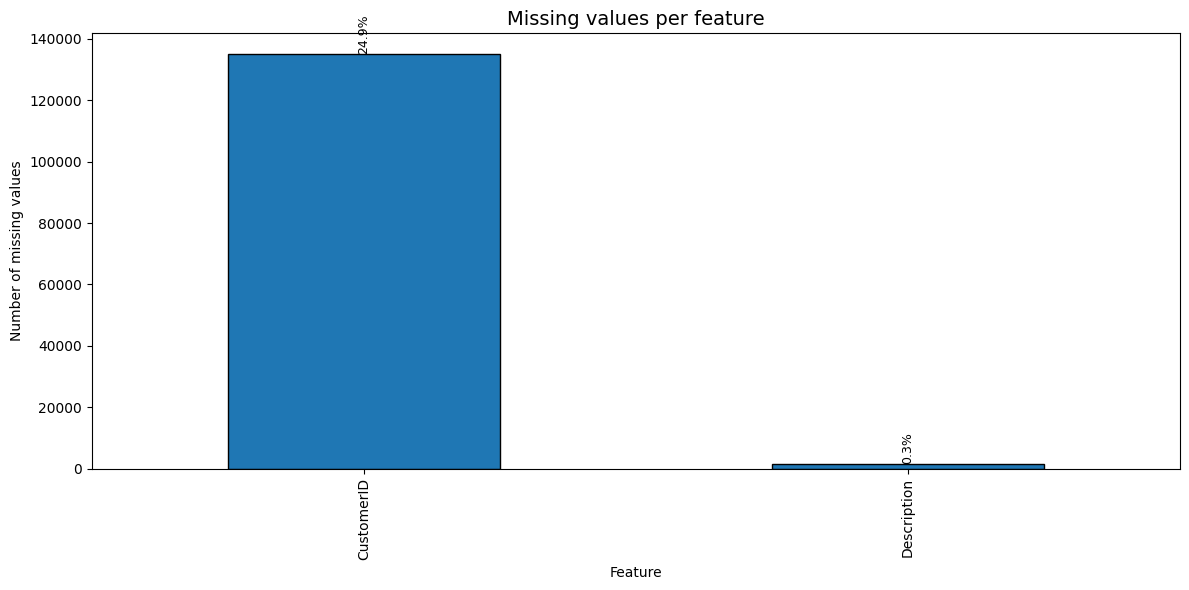

In [240]:
# plotting missing values
plot_missing_values(raw_df)

In [241]:
df = raw_df.copy()


df["CustomerID"] = df["CustomerID"].astype(str).str.strip()

# Drop rows without CustomerID for this analysis
df = df[df["CustomerID"].notna() & (df["CustomerID"] != "nan")]

# Count unique invoices per customer
invoices_per_customer = (
    df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

# Keep customers with more than one invoice
multi_invoice_customers = invoices_per_customer[invoices_per_customer > 1]

print(f"Number of customers with >1 invoice: {len(multi_invoice_customers)}")

# Display top customers
display(
    multi_invoice_customers
    .rename("n_invoices")
    .to_frame()
    .head(20)
)

Number of customers with >1 invoice: 3059


,n_invoices
CustomerID,
14911.0,248
12748.0,224
17841.0,169
14606.0,128
15311.0,118
13089.0,118
12971.0,89
14527.0,86
13408.0,81


In [242]:
# =========================================
# InvoiceNo with mixed missingness in CustomerID
# =========================================

df = raw_df.copy()

# Normalize CustomerID
df["CustomerID"] = df["CustomerID"].astype(str).str.strip()
is_missing_customer = df["CustomerID"].isna() | (df["CustomerID"] == "nan")

invoice_customer_missingness = (
    df.assign(customer_missing=is_missing_customer)
      .groupby("InvoiceNo")["customer_missing"]
      .agg(["any", "all", "count"])
)

# Invoices with BOTH missing and non-missing CustomerID
mixed_customerid_invoices = invoice_customer_missingness[
    (invoice_customer_missingness["any"]) &
    (~invoice_customer_missingness["all"])
]

print(f"Number of InvoiceNo with mixed CustomerID missingness: {len(mixed_customerid_invoices)}")

display(mixed_customerid_invoices.head(20))


Number of InvoiceNo with mixed CustomerID missingness: 0


,any,all,count
InvoiceNo,,,


In [243]:
def _normalize_customer_id(customer_id: pd.Series) -> pd.Series:
    return customer_id.astype(str).str.strip()

def prepare_transactions(df: pd.DataFrame, drop_missing_customer: bool = True) -> pd.DataFrame:
    """Clean raw transactions and add helper columns."""
    transactions = df.copy()
    transactions["InvoiceNo"] = transactions["InvoiceNo"].astype(str).str.strip()
    transactions["StockCode"] = transactions["StockCode"].astype(str).str.strip()
    transactions["Description"] = transactions["Description"].fillna("Unknown")
    transactions["CustomerID"] = _normalize_customer_id(transactions["CustomerID"])
    if drop_missing_customer:
        transactions = transactions[
            transactions["CustomerID"].notna()
            & (transactions["CustomerID"].str.len() > 0)
            & (transactions["CustomerID"].str.lower() != "nan")
        ]

    transactions["InvoiceDate"] = pd.to_datetime(transactions["InvoiceDate"], errors="coerce")
    transactions["Quantity"] = pd.to_numeric(transactions["Quantity"], errors="coerce")
    transactions["UnitPrice"] = pd.to_numeric(transactions["UnitPrice"], errors="coerce")
    transactions["is_cancellation"] = (
        transactions["InvoiceNo"].str.startswith("C") | (transactions["Quantity"] < 0)
    )
    transactions["Revenue"] = transactions["Quantity"] * transactions["UnitPrice"]
    return transactions




In [244]:
transactions = prepare_transactions(raw_df, drop_missing_customer=True)
print(transactions.dtypes)
transactions.isna().sum()
transactions.to_csv("outputs/transactions_cleaned.csv", index=False)

InvoiceNo                  object
StockCode                  object
Description                object
Quantity                    int64
InvoiceDate        datetime64[ns]
UnitPrice                 float64
CustomerID                 object
Country                    object
is_cancellation              bool
Revenue                   float64
dtype: object


In [245]:
transactions.agg(
    {
        "InvoiceDate": ["min", "max"],
        "Quantity": ["min", "max", "mean"],
        "UnitPrice": ["min", "max", "mean"],
        "Revenue": ["min", "max", "mean"],
    }
)


,InvoiceDate,Quantity,UnitPrice,Revenue
min,2010-12-01 08:26:00,-80995.000,0.00,-168469.600
max,2011-12-09 12:50:00,80995.000,38970.00,168469.600
mean,NaT,12.061,3.46,20.402


## Exploratory data analysis

In [246]:
plot_histogram(transactions["Quantity"], "Quantity distribution", FIGURES_DIR / "quantity_hist.png")
transactions["Quantity"].describe()


count    406829.000
mean         12.061
std         248.693
min      -80995.000
25%           2.000
50%           5.000
75%          12.000
max       80995.000
Name: Quantity, dtype: float64

In [247]:
plot_histogram(
    transactions["UnitPrice"],
    "Unit price distribution",
    FIGURES_DIR / "unitprice_hist.png",
    log_scale=True,
)
transactions["UnitPrice"].describe()


count    406829.000
mean          3.460
std          69.315
min           0.000
25%           1.250
50%           1.950
75%           3.750
max       38970.000
Name: UnitPrice, dtype: float64

In [248]:
plot_histogram(
    transactions["Revenue"],
    "Revenue distribution",
    FIGURES_DIR / "revenue_hist.png",
    log_scale=True,
)
transactions["Revenue"].describe()


count    406829.000
mean         20.402
std         427.592
min     -168469.600
25%           4.200
50%          11.100
75%          19.500
max      168469.600
Name: Revenue, dtype: float64

In [249]:
country_counts = transactions.groupby("Country").size().sort_values(ascending=False).head(10)
plot_bar(country_counts.index, country_counts.values, "Top countries by transactions", "Transactions", FIGURES_DIR / "country_transactions.png")
country_counts


Country
United Kingdom    361878
Germany             9495
France              8491
EIRE                7485
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         1877
Portugal            1480
Australia           1259
dtype: int64

In [250]:
country_revenue = transactions.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(10)
plot_bar(country_revenue.index, country_revenue.values, "Top countries by revenue", "Revenue", FIGURES_DIR / "country_revenue.png")
country_revenue


Country
United Kingdom    6.768e+06
Netherlands       2.847e+05
EIRE              2.503e+05
Germany           2.217e+05
France            1.967e+05
Australia         1.371e+05
Switzerland       5.574e+04
Spain             5.477e+04
Belgium           4.091e+04
Sweden            3.660e+04
Name: Revenue, dtype: float64

In [251]:
cancel_rate = transactions["is_cancellation"].mean()
print(f"Overall cancellation rate: {cancel_rate:.2%}")
country_cancel = transactions.groupby("Country")["is_cancellation"].mean().sort_values(ascending=False).head(10)
plot_bar(country_cancel.index, country_cancel.values, "Cancellation rate by country", "Cancellation rate", FIGURES_DIR / "country_cancellation.png")
country_cancel


Overall cancellation rate: 2.19%


Country
USA               0.385
Czech Republic    0.167
Malta             0.118
Japan             0.103
Saudi Arabia      0.100
Australia         0.059
Italy             0.056
Germany           0.048
EIRE              0.033
Poland            0.032
Name: is_cancellation, dtype: float64

In [252]:
daily_counts = transactions.set_index("InvoiceDate").resample("D").size()
plot_time_series(daily_counts.index, daily_counts.values, "Transactions per day", "Transactions", FIGURES_DIR / "transactions_per_day.png")
daily_counts.describe()


count     374.000
mean     1087.778
std       761.041
min         0.000
25%       707.250
50%      1062.500
75%      1449.000
max      3434.000
dtype: float64

In [253]:
weekly_counts = transactions.set_index("InvoiceDate").resample("W").size()
plot_time_series(weekly_counts.index, weekly_counts.values, "Transactions per week", "Transactions", FIGURES_DIR / "transactions_per_week.png")
weekly_counts.describe()


count       54.000
mean      7533.870
std       3334.411
min          0.000
25%       5521.750
50%       6605.500
75%       8618.000
max      16320.000
dtype: float64

In [254]:
cust_invoice_counts = transactions.groupby(["CustomerID", "InvoiceNo"]).size().groupby("CustomerID").size()
plot_histogram(cust_invoice_counts, "Invoices per customer", FIGURES_DIR / "invoices_per_customer.png")
cust_invoice_counts.describe()


count    4372.000
mean        5.075
std         9.339
min         1.000
25%         1.000
50%         3.000
75%         5.000
max       248.000
dtype: float64

## Cutoff selection and label definition
Use the 80th percentile of `InvoiceDate` as the cutoff and label customers based on purchases in the next 30 days.

In [255]:
config = LabelingConfig(label_window_days=30)
dataset, cutoff_date = build_dataset(transactions, config)
print(f"Cutoff date: {cutoff_date:%Y-%m-%d}")
print(f"Dataset shape: {dataset.shape}")
dataset.head()


Cutoff date: 2011-10-31
Dataset shape: (4001, 14)


,CustomerID,recency_days,frequency,active_span_days,monetary_value,avg_basket_size,unique_products,avg_unit_price,std_unit_price,interpurchase_mean_days,interpurchase_std_days,cancellation_ratio,country_mode,label
0,17850.0,332.0,34.0,1.0,5391.21,50.971,21.0,3.960,5.608,0.000,0.000,0.029,United Kingdom,0
1,13047.0,16.0,9.0,317.0,3232.59,154.444,105.0,3.926,2.862,39.375,26.683,0.438,United Kingdom,1
2,12583.0,18.0,12.0,315.0,5414.44,334.667,97.0,3.172,4.483,28.273,19.085,0.200,France,1
3,13748.0,55.0,5.0,278.0,948.25,87.800,24.0,3.996,4.247,69.250,72.201,0.000,United Kingdom,0
4,15100.0,293.0,3.0,40.0,876.00,26.667,1.0,10.950,0.000,19.500,17.678,0.500,United Kingdom,0


In [256]:
print(f"Cutoff date (T): {cutoff_date:%Y-%m-%d}")
min_date = pd.to_datetime(transactions["InvoiceDate"]).min()
max_date = pd.to_datetime(transactions["InvoiceDate"]).max()
print(f"InvoiceDate min: {min_date:%Y-%m-%d}")
print(f"InvoiceDate max: {max_date:%Y-%m-%d}")
print(f"Quantile used for original cutoff: {config.percentile_cutoff}")
history_days = (cutoff_date - min_date).days
label_window_days = config.label_window_days
print(f"History coverage (min -> T): {history_days} days")
print(f"Label window (T -> T+{label_window_days}): {label_window_days} days")


Cutoff date (T): 2011-10-31
InvoiceDate min: 2010-12-01
InvoiceDate max: 2011-12-09
Quantile used for original cutoff: 0.8
History coverage (min -> T): 333 days
Label window (T -> T+30): 30 days


In [257]:
dataset["label"].value_counts(normalize=True).rename("proportion")


label
0    0.667
1    0.333
Name: proportion, dtype: float64

In [258]:
dataset.describe(include='all')


,CustomerID,recency_days,frequency,active_span_days,monetary_value,avg_basket_size,unique_products,avg_unit_price,std_unit_price,interpurchase_mean_days,interpurchase_std_days,cancellation_ratio,country_mode,label
count,4001,4001.000,4001.000,4001.000,4001.000,4001.000,4001.000,4001.000,4001.000,4001.000,4001.000,4001.000,4001,4001.000
unique,4001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37,NaN
top,17850.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,United Kingdom,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3614,NaN
mean,NaN,95.636,3.758,106.917,1799.138,246.571,55.122,4.591,4.401,171.909,15.677,0.116,NaN,0.333
std,NaN,95.756,6.570,114.702,7779.202,1209.537,76.539,35.651,19.540,136.881,27.277,0.190,NaN,0.471
min,NaN,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,NaN,0.000
25%,NaN,20.000,1.000,0.000,283.530,90.000,14.000,2.226,1.750,42.333,0.000,0.000,NaN,0.000
50%,NaN,53.000,2.000,64.000,618.270,160.000,32.000,2.959,2.622,109.000,0.000,0.000,NaN,0.000
75%,NaN,156.000,4.000,210.000,1506.430,273.000,69.000,3.911,3.553,333.000,23.768,0.200,NaN,1.000


## Modeling
Split customers, fit baseline models, and capture core metrics with calibration checks.

In [259]:
X_train, X_val, X_test, y_train, y_val, y_test = split_dataset(
    dataset, test_size=0.2, val_size=0.2, random_state=42
)
preprocessor = build_preprocessor()
pipelines = train_models(X_train, y_train, preprocessor)
list(pipelines.keys())


['log_reg', 'gb']

In [260]:
thresholds = {
    name: find_best_threshold_f1(pipe, X_val, y_val)
    for name, pipe in pipelines.items()
}
results = {}
for name, pipe in pipelines.items():
    best_threshold, best_f1_val = thresholds[name]
    metrics = evaluate_model(pipe, X_test, y_test, threshold=best_threshold)
    metrics["best_threshold"] = best_threshold
    metrics["best_f1_val"] = best_f1_val
    results[name] = metrics
pd.DataFrame(
    [
        {
            "model": name,
            "roc_auc": metrics["roc_auc"],
            "pr_auc": metrics["pr_auc"],
            "best_threshold": metrics["best_threshold"],
            "best_f1_val": metrics["best_f1_val"],
            "f1_at_threshold": metrics["f1_at_threshold"],
            "brier_score": metrics["brier_score"],
        }
        for name, metrics in results.items()
    ]
)


,model,roc_auc,pr_auc,best_threshold,best_f1_val,f1_at_threshold,brier_score
0,log_reg,0.718,0.612,0.469,0.580,0.556,0.205
1,gb,0.699,0.597,0.290,0.555,0.533,0.193


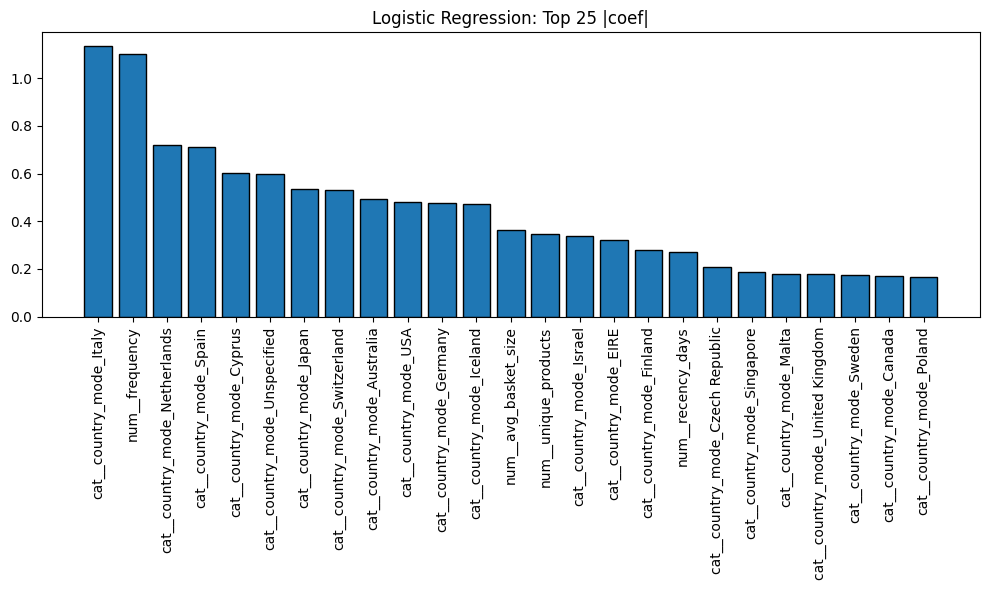

Top positive coefficients:
cat__country_mode_Italy: 1.1352
num__frequency: 1.1013
cat__country_mode_Netherlands: 0.7192
cat__country_mode_Spain: 0.7129
cat__country_mode_Japan: 0.5341
cat__country_mode_Germany: 0.4767
cat__country_mode_Iceland: 0.4706
num__unique_products: 0.3476
cat__country_mode_United Kingdom: 0.1775
cat__country_mode_Sweden: 0.1739
Top negative coefficients:
cat__country_mode_Cyprus: -0.6042
cat__country_mode_Unspecified: -0.5985
cat__country_mode_Switzerland: -0.5299
cat__country_mode_Australia: -0.4944
cat__country_mode_USA: -0.4804
num__avg_basket_size: -0.3631
cat__country_mode_Israel: -0.3386
cat__country_mode_EIRE: -0.3198
cat__country_mode_Finland: -0.2792
num__recency_days: -0.2725


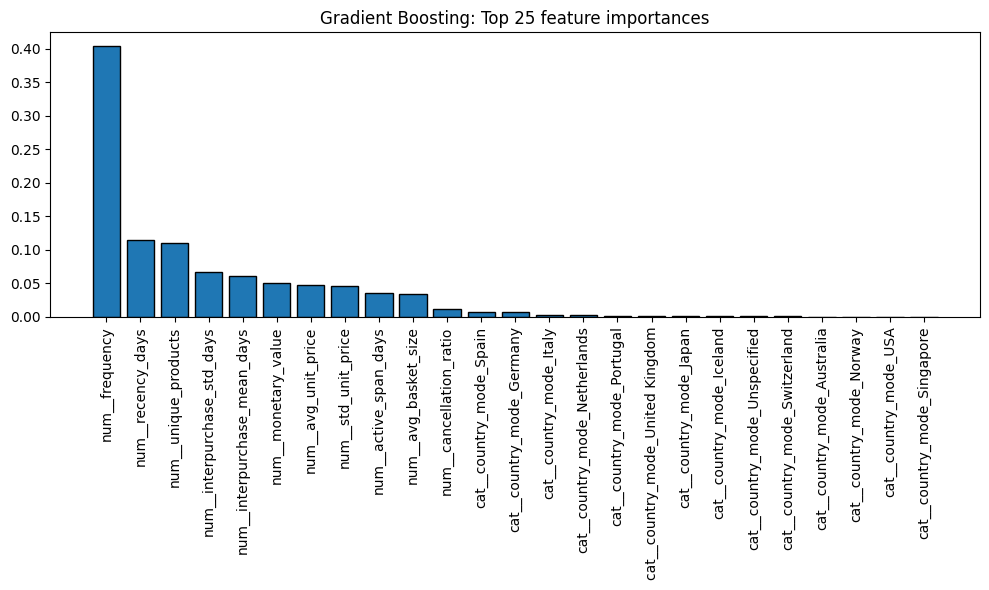

In [261]:
feature_names = pipelines["log_reg"].named_steps["preprocessor"].get_feature_names_out()
log_reg_coef = pipelines["log_reg"].named_steps["model"].coef_[0]
abs_coef = np.abs(log_reg_coef)
top_idx = np.argsort(abs_coef)[-25:][::-1]
plt.figure(figsize=(10, 6))
plt.bar(range(len(top_idx)), abs_coef[top_idx], tick_label=feature_names[top_idx], edgecolor="black")
plt.xticks(rotation=90)
plt.title("Logistic Regression: Top 25 |coef|")
plt.tight_layout()
plt.show()
top_positive_idx = np.argsort(log_reg_coef)[-10:][::-1]
top_negative_idx = np.argsort(log_reg_coef)[:10]
print("Top positive coefficients:")
for i in top_positive_idx:
    print(f"{feature_names[i]}: {log_reg_coef[i]:.4f}")
print("Top negative coefficients:")
for i in top_negative_idx:
    print(f"{feature_names[i]}: {log_reg_coef[i]:.4f}")

gb_importances = pipelines["gb"].named_steps["model"].feature_importances_
top_gb_idx = np.argsort(gb_importances)[-25:][::-1]
plt.figure(figsize=(10, 6))
plt.bar(range(len(top_gb_idx)), gb_importances[top_gb_idx], tick_label=feature_names[top_gb_idx], edgecolor="black")
plt.xticks(rotation=90)
plt.title("Gradient Boosting: Top 25 feature importances")
plt.tight_layout()
plt.show()


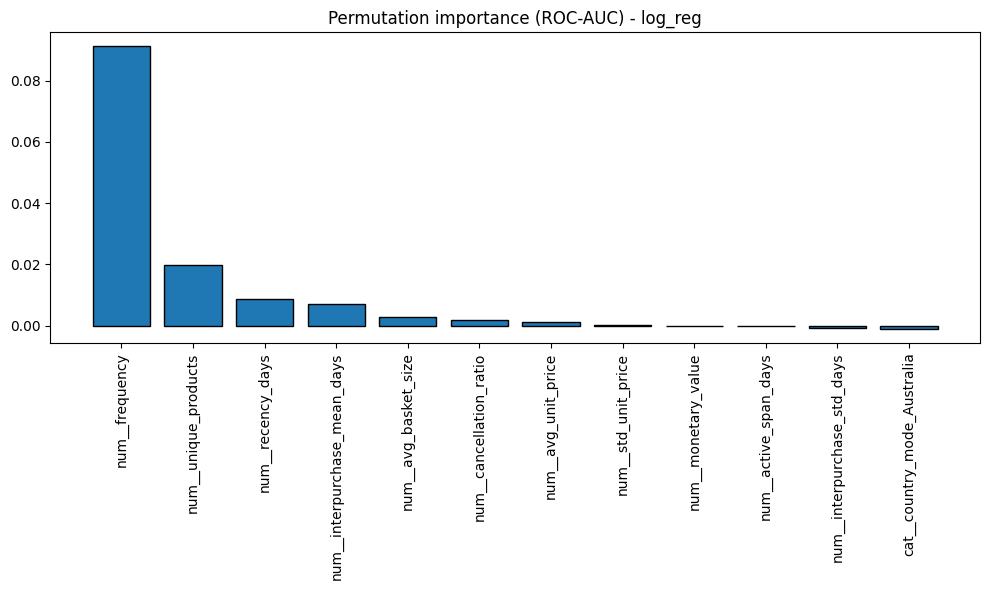

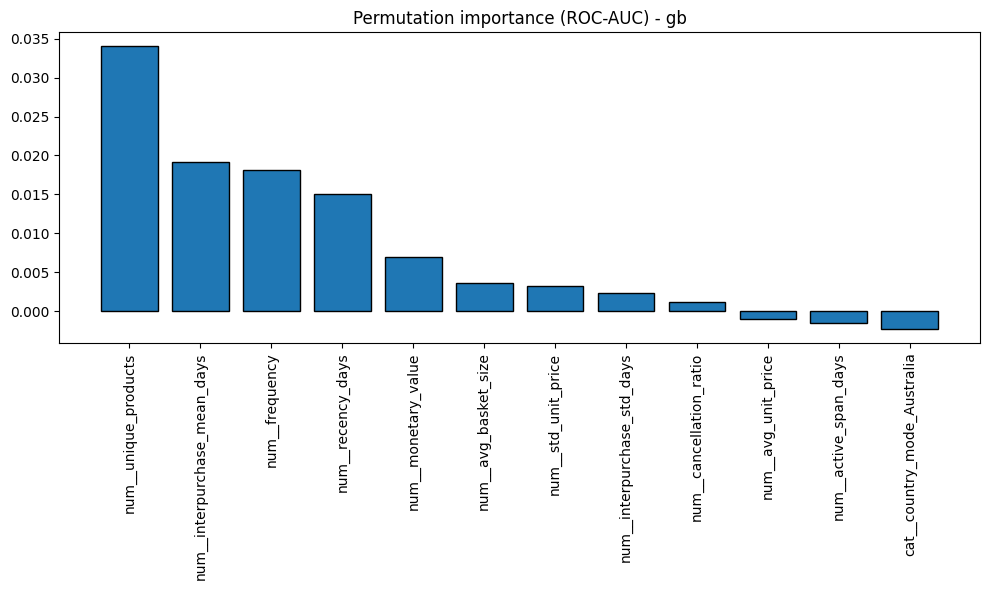

In [262]:
from sklearn.inspection import permutation_importance
perm_results = {}
for name, pipe in pipelines.items():
    perm = permutation_importance(
        pipe, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42
    )
    perm_results[name] = perm
    feature_names = pipe.named_steps["preprocessor"].get_feature_names_out()
    top_idx = np.argsort(perm.importances_mean)[-25:][::-1]
    plt.figure(figsize=(10, 6))
    plt.bar(range(len(top_idx)), perm.importances_mean[top_idx], tick_label=feature_names[top_idx], edgecolor="black")
    plt.xticks(rotation=90)
    plt.title(f"Permutation importance (ROC-AUC) - {name}")
    plt.tight_layout()
    plt.show()


In [263]:
best_model_name = select_best_model(results)
best_pipeline = pipelines[best_model_name]
best_metrics = results[best_model_name]
print(f"Best model: {best_model_name}")


Best model: log_reg


In [264]:
plot_confusion_matrix(
    best_metrics["confusion_matrix"],
    f"Confusion matrix ({best_model_name})",
    FIGURES_DIR / f"confusion_{best_model_name}.png",
)
plot_reliability_curve(
    best_metrics["calibration_curve"][0],
    best_metrics["calibration_curve"][1],
    f"Reliability curve ({best_model_name})",
    FIGURES_DIR / f"reliability_{best_model_name}.png",
)
print(f"Brier score: {best_metrics['brier_score']:.4f}")


Brier score: 0.2050


In [265]:
save_model(best_pipeline, MODELS_DIR / "model.joblib")
print("Saved best pipeline to outputs/models/model.joblib")


Saved best pipeline to outputs/models/model.joblib


In [266]:

def generate_time_cutoffs(transactions: pd.DataFrame, label_window_days: int = 30, freq: str = "ME") -> list[pd.Timestamp]:
    """Generate calendar-based cutoff dates where the label window stays inside observed data."""
    invoice_dates = pd.to_datetime(transactions["InvoiceDate"])
    max_date = invoice_dates.max()
    min_date = invoice_dates.min().normalize()
    cutoffs: list[pd.Timestamp] = []
    for cutoff in pd.date_range(min_date, max_date, freq=freq):
        cutoff = pd.Timestamp(cutoff)
        if cutoff + pd.Timedelta(days=label_window_days) > max_date:
            continue
        if (invoice_dates <= cutoff).any():
            cutoffs.append(cutoff)
    return cutoffs

def run_rolling_time_evaluation(
    transactions: pd.DataFrame,
    cutoff_dates: Sequence[pd.Timestamp] | None,
    *,
    label_window_days: int = 30,
    test_size: float = 0.2,
    val_size: float = 0.2,
    random_state: int = 42,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Run rolling evaluation over multiple cutoff dates without leaking future data."""
    if not cutoff_dates:
        return pd.DataFrame(), pd.DataFrame()
    tx = transactions.copy()
    tx["InvoiceDate"] = pd.to_datetime(tx["InvoiceDate"])
    results: list[dict[str, object]] = []
    for cutoff in cutoff_dates:
        try:
            features = engineer_customer_features(tx, cutoff)
        except ValueError:
            continue
        labels = build_labels(
            tx,
            cutoff,
            label_window_days=label_window_days,
            customer_ids=features["CustomerID"].values,
        )
        dataset = features.merge(labels, on="CustomerID", how="left").fillna({"label": 0})
        if dataset["label"].nunique() < 2:
            continue
        try:
            X_train, X_val, X_test, y_train, y_val, y_test = split_dataset(
                dataset,
                test_size=test_size,
                val_size=val_size,
                random_state=random_state,
            )
        except ValueError:
            continue
        preprocessor = build_preprocessor()
        pipelines = train_models(X_train, y_train, preprocessor)
        for model_name, pipeline in pipelines.items():
            best_threshold, _ = find_best_threshold_f1(pipeline, X_val, y_val)
            metrics = evaluate_model(pipeline, X_test, y_test, threshold=best_threshold)
            results.append(
                {
                    "cutoff_date": cutoff,
                    "model": model_name,
                    "roc_auc": metrics["roc_auc"],
                    "pr_auc": metrics["pr_auc"],
                    "brier_score": metrics["brier_score"],
                }
            )
    metrics_df = pd.DataFrame(results)
    if metrics_df.empty:
        return metrics_df, metrics_df
    summary_df = (
        metrics_df.groupby("model")[["roc_auc", "pr_auc", "brier_score"]]
        .agg(["mean", "std"])
    )
    summary_df.columns = [f"{metric}_{stat}" for metric, stat in summary_df.columns]
    summary_df = summary_df.reset_index()
    return metrics_df, summary_df


### Rolling time-based evaluation
Run monthly, leakage-free evaluation windows using the existing pipelines.


In [267]:

rolling_cutoff_dates = generate_time_cutoffs(transactions, label_window_days=30, freq="ME")
metrics_df, summary_df = run_rolling_time_evaluation(
    transactions,
    cutoff_dates=rolling_cutoff_dates,
    label_window_days=30,
    test_size=0.2,
    random_state=42,
)
metrics_df
summary_df


,model,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,brier_score_mean,brier_score_std
0,gb,0.720,0.036,0.571,0.034,0.173,0.019
1,log_reg,0.721,0.049,0.567,0.051,0.202,0.013
